In [1]:
import math
from mhcgnomes import parse
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)

METHOD = "hmm_pomegranate"


# 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/"


In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*02:01']

In [4]:
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None


def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None


per_allele_decoy = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    
    per_allele_decoy[allele_name] = decoy_df.copy()


In [5]:
per_allele_decoy[ALLELES[0]].length.value_counts()

8     40363
10    40199
9     40024
11    39765
12    39649
Name: length, dtype: int64

# 2. Read models

In [6]:
from hmm_logic_methods import load_model

In [7]:

RUNS = 2
TARGET_LENGTH = 9
STATE_VARIANTS = [15, 18]

total_splits = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]])

BAUM_WELCH_MODELS_BINDING = [f"{i}_run-{TARGET_LENGTH}-{state_variant}-st-baum-welch-alg-30-min_iters"
                        for i in range(RUNS)
                        for state_variant in STATE_VARIANTS]

BAUM_WELCH_MODELS_IMMUNOGENIC = [f"{i}_run_imm-{TARGET_LENGTH}-{state_variant}-st-baum-welch-alg-30-min_iters"
                             for i in range(RUNS)
                             for state_variant in STATE_VARIANTS]


# 0_run-8-12-st-viterbi-alg-None-batches-1-batch_size-None-init_batch_size-0.0-lr-0.0-edge_inertia-0.0-distribution_inertia-0.0-emission_pseudocount-0.0-transition_pseudocount-30-min_iters-False-use_pseudocount_model-HLA_A_02_01-0
# BAUM_WELCH_MODELS_12 = [f"{i}_run-8-12-st-baum-welch-alg-30-min_iters" for i in range(RUNS)]
# BAUM_WELCH_MODELS_15 = [f"{i}_run-8-15-st-baum-welch-alg-30-min_iters" for i in range(RUNS)]
#
# BAUM_WELCH_MODELS_20 = [f"{i}_run-8-20-st-baum-welch-alg-30-min_iters" for i in range(RUNS)]

#
#
MODEL_PREFIX_TO_READ = BAUM_WELCH_MODELS_BINDING \
                         +  BAUM_WELCH_MODELS_IMMUNOGENIC

per_name_model = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for model_to_read in MODEL_PREFIX_TO_READ:
            for split_num in range(total_splits):
                model_name = f"{model_to_read}_model-{target_allele_name}-{split_num}"
                model = load_model(TARGET_PATH_TO_RESULTS, model_name)
                per_name_model[model_name] = model
                # print(model_name)



# Populate scores for models

12 states

In [8]:
models_params_string= "baum-welch-alg-30-min_iters"



def get_models(base_model_prefix, params_string):
    per_allele_per_run_per_split_prepared_models = dict()
    for allele_name in ALLELES:
        per_allele_per_run_per_split_prepared_models[allele_name] = dict()
        for run_num in range(RUNS):
            per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
            for split_num, per_length_data in per_allele_per_kfold_per_length_binders_train[allele_name].items():
                target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
                base_model_name = f"{run_num}_run{base_model_prefix}-{params_string}_model-{target_allele_name}-{split_num}"

                base_model = per_name_model[base_model_name]
                per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = base_model
    return per_allele_per_run_per_split_prepared_models

base_model_prefix = f"-{TARGET_LENGTH}-15-st"
per_allele_per_run_per_split_prepared_models15 = get_models(base_model_prefix, models_params_string)


base_model_prefix = f"-{TARGET_LENGTH}-18-st"
per_allele_per_run_per_split_prepared_models18 = get_models(base_model_prefix, models_params_string)


base_model_prefix = f"_imm-{TARGET_LENGTH}-15-st"
per_allele_per_run_per_split_prepared_models_imm15 = get_models(base_model_prefix, models_params_string)


base_model_prefix = f"_imm-{TARGET_LENGTH}-18-st"
per_allele_per_run_per_split_prepared_models_imm18 = get_models(base_model_prefix, models_params_string)

# base_model_prefix = "8-20-st"
# per_allele_per_run_per_split_prepared_models20 = get_models(base_model_prefix, models_params_string)

In [19]:
def get_decoy_scores(per_allele_per_run_per_split_models, per_allele_decoy_data, target_length):
    per_allele_per_run_per_split_decoy_scores_df = dict()

    for allele_name, per_run_num_per_split_models in per_allele_per_run_per_split_models.items():
        per_allele_per_run_per_split_decoy_scores_df[allele_name] = dict()
        data = per_allele_decoy_data[allele_name]

        assert 'peptide' in data.columns
        assert 'length' in data.columns
        target_data = data[data['length'] == target_length].copy()

        for run_num, per_split_models in per_run_num_per_split_models.items():
            print(f"For run {run_num}:", end=" ")
            per_allele_per_run_per_split_decoy_scores_df[allele_name][run_num] = dict()
            for split_num, model in per_split_models.items():
                print(f"split {split_num}", end=" ")
                score_df = target_data.copy()
                score_df['score'] = [model.log_probability(peptide) for peptide in score_df['peptide']]
                per_allele_per_run_per_split_decoy_scores_df[allele_name][run_num][split_num] = score_df
            print()
    return per_allele_per_run_per_split_decoy_scores_df
    
    

In [15]:
import numpy as np

scores

In [75]:
import math
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import jaccard_score

def binary_confusion_matrix(y_actual, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true=y_actual, y_pred=y_pred).ravel()
    return tp, fp, tn, fn


def get_percentile_ranks(scores, ref_scores):
    ref_scores = ref_scores.sort_values()
    pct_increment = 1./len(ref_scores)
    percentile_column_name = 'percentile_rank'
    percentile_ranks = (0.5 + 0.5*ref_scores.searchsorted(scores, side='left') + 0.5 * ref_scores.searchsorted(scores, side='right'))*pct_increment
    percentile_ranks = 100 - percentile_ranks*100
    return percentile_ranks

def get_binders_nonbinders_decoy_df(binders_source, non_binders_source, decoy_source, allele_name, split_num, dataset_type):
   
    binders = pd.DataFrame( {"peptide": binders_source[allele_name][split_num][TARGET_LENGTH], "data_type":"binder"})
    non_binders = pd.DataFrame( {"peptide": non_binders_source[allele_name][split_num][TARGET_LENGTH], "data_type":"non-binder"})
    # just take different subsamples from decoy
    if dataset_type == "Train":
        decoy_data = decoy_source[allele_name][0][split_num]['peptide'].values[:len(binders)]
    else:
        decoy_data = decoy_source[allele_name][0][split_num]['peptide'].values[-len(binders):]
    
    decoy = pd.DataFrame( {"peptide": decoy_data, "data_type":"decoy"})
    print(f"Initialized {dataset_type} dataset of ({len(binders)},{len(non_binders)},{len(decoy)})")

    return pd.concat([binders, non_binders, decoy])
    
def get_metrics_for_pair_of_subsets(positive_percentiles, negative_percentiles, test_prefix):
    print(f"\tCollect metrics for {test_prefix}")
    metrics = dict()
    y_actual = np.concatenate([np.ones(len(positive_percentiles), dtype=int), np.zeros(len(negative_percentiles), dtype=int)])
    y_pred =  np.concatenate([ (positive_percentiles < 2).astype(int), (negative_percentiles < 2).astype(int)])
    
              #based on fscore
    precision, recall, thresholds = precision_recall_curve(y_true=y_actual, probas_pred=y_pred)
#                 print( precision, recall)
    # convert to f score
    fscore = np.divide((2 * precision * recall), precision + recall, out=np.zeros_like(precision), where=precision + recall!=0)
    # locate the index of the largest f score
    ix = np.argmax(fscore)
    #best_thresh = thresholds[ix]
    best_thresh = 0.5
    rounded_y_pred = [1 if i >= best_thresh  else 0 for i in y_pred]
    
    accuracy_score_value = accuracy_score(y_true=y_actual, y_pred=rounded_y_pred)
    f1_score_value = f1_score(y_true=y_actual, y_pred=rounded_y_pred)
    precision_score_value = precision_score(y_true=y_actual, y_pred=rounded_y_pred, pos_label=1, zero_division=0)
    recall_score_value = recall_score(y_true=y_actual, y_pred=rounded_y_pred)
    roc_auc_score_value = roc_auc_score(y_true=y_actual, y_score=y_pred)
    
    
    metrics[f"{test_prefix}_pr"] = precision_score_value
    metrics[f"{test_prefix}_recall"] = recall_score_value
    metrics[f"{test_prefix}_f1"] = f1_score_value
    metrics[f"{test_prefix}_acc"] = accuracy_score_value
    metrics[f"{test_prefix}_roc-auc"] = roc_auc_score_value
    metrics[f"{test_prefix}_shape"] = f"{len(positive_percentiles)}_vs_{len(negative_percentiles)}"
    return metrics
    

def collect_summary_statistics(prediction_df, score_column, percentile_column, prefix="Train"):

    binders_scores = prediction_df.loc[prediction_df['data_type'] == 'binder', score_column]
    binders_percentiles = prediction_df.loc[prediction_df['data_type'] == 'binder', percentile_column]
    sum_binders_score = sum(binders_scores)
    mean_binders_score = binders_scores.median()
    
    non_binders_scores = prediction_df.loc[prediction_df['data_type'] == 'non-binder', score_column]
    non_binders_percentiles = prediction_df.loc[prediction_df['data_type'] == 'non-binder', percentile_column]
    sum_non_binders_score = sum(non_binders_scores)
    mean_non_binders_score = non_binders_scores.median()
    
    
    decoy_sample_scores = prediction_df.loc[prediction_df['data_type'] == 'decoy', score_column]
    decoy_sample_percentiles = prediction_df.loc[prediction_df['data_type'] == 'decoy', percentile_column]
    sum_decoy_sample_score = sum(decoy_sample_scores)
    mean_decoy_score = decoy_sample_scores.median()
    print(f"Get summary statistics for {prefix}, data shape {prediction_df.shape}, B/N/D {len(binders_scores)},{len(non_binders_scores)},{len(decoy_sample_scores)}")
    row = { f"{prefix}_sum_B_lp": sum_binders_score,
            f"{prefix}_median_B_lp": mean_binders_score,
            f"{prefix}_sum_NB_lp": sum_non_binders_score,
            f"{prefix}_median_NB_lp": mean_non_binders_score,
            f"{prefix}_sum_D_lp": sum_decoy_sample_score,
            f"{prefix}_median_D_lp": mean_decoy_score,

    }
    metrics = dict()
    #BvD
    aux_metrics = get_metrics_for_pair_of_subsets(binders_percentiles, decoy_sample_percentiles, "BvD")
    metrics.update(aux_metrics)
    aux_metrics = get_metrics_for_pair_of_subsets(binders_percentiles, non_binders_percentiles, "BvN")
    metrics.update(aux_metrics)
    
    # jaccard_score_value = jaccard_score(y_true=y_actual, y_pred=rounded_y_pred)

    for name, metric_value in metrics.items():
        row[f"{prefix}_{name}"] = metric_value
        
    return row

    
    
    
    
    

def get_log_scores_df(per_allele_per_run_per_split_models, per_allele_per_run_per_split_decoy_scores):
    df = pd.DataFrame()
    # df = pd.DataFrame(columns=[ "allele", "split", "run","train_lp_score","train_vi_score" ,"train_map_score" , "test_lp_score", "test_vi_score", "test_map_score", "model_name","sum_lp_score", "sum_vi_score", "sum_map_score"])

    per_allele_per_split_train_predictions = dict()
    per_allele_per_split_test_predictions = dict()

    for allele_name, per_run_per_split_models in per_allele_per_run_per_split_models.items():
        per_allele_per_split_train_predictions[allele_name] = dict()
        per_allele_per_split_test_predictions[allele_name] = dict()
        
        # init predictions dfs (make combination of binders, non-binders, decoy)
        for split_num in range(total_splits):
            per_allele_per_split_train_predictions[allele_name][split_num] = get_binders_nonbinders_decoy_df(per_allele_per_kfold_per_length_binders_train,
                                                per_allele_per_kfold_per_length_non_binders_train,
                                                per_allele_per_run_per_split_decoy_scores,
                                                allele_name,
                                                split_num,
                                                "Train"
                                                )
            per_allele_per_split_test_predictions[allele_name][split_num] = get_binders_nonbinders_decoy_df(per_allele_per_kfold_per_length_binders_test,
                                                per_allele_per_kfold_per_length_non_binders_test,
                                                per_allele_per_run_per_split_decoy_scores,
                                                allele_name,
                                                split_num,
                                                "Test"
                                                )

        for run_num, per_split_models in per_run_per_split_models.items():
            
            for split_num, model in per_split_models.items():
                print(f"run {run_num}, split {split_num}")
                row = dict()
                row["allele"] = allele_name
                row["run"] = run_num
                row["split"] = split_num

                # scores and percentiles for each peptide
                train_data_points  = per_allele_per_split_train_predictions[allele_name][split_num]['peptide'].values
                test_data_points  = per_allele_per_split_test_predictions[allele_name][split_num]['peptide'].values
                
                train_lp_scores = [model.log_probability(peptide) for peptide in train_data_points]
                test_lp_scores = [model.log_probability(peptide) for peptide in test_data_points]
                
                
                ref_scores = per_allele_per_run_per_split_decoy_scores[allele_name][run_num][split_num]['score'].copy()

                per_allele_per_split_train_predictions[allele_name][split_num][f'score_lp_{run_num}'] = train_lp_scores
                per_allele_per_split_train_predictions[allele_name][split_num][f'percentile_lp{run_num}'] = get_percentile_ranks(train_lp_scores, ref_scores)
                
                
                                
                row_train = collect_summary_statistics( per_allele_per_split_train_predictions[allele_name][split_num],
                                                 score_column=f'score_lp_{run_num}', 
                                                 percentile_column=f'percentile_lp{run_num}' , prefix="Train")
                
                
                per_allele_per_split_test_predictions[allele_name][split_num][f'score_lp_{run_num}'] = test_lp_scores
                per_allele_per_split_test_predictions[allele_name][split_num][f'percentile_lp{run_num}'] = get_percentile_ranks(test_lp_scores, ref_scores)
                
                row_test = collect_summary_statistics( per_allele_per_split_test_predictions[allele_name][split_num],
                                 score_column=f'score_lp_{run_num}', 
                                 percentile_column=f'percentile_lp{run_num}', prefix="Test" )
                
                row.update(row_train)
                row.update(row_test)

                row["model_name"] = model.name
                
                df = df.append(row, ignore_index=True)
                
                # per_allele_per_split_train_predictions[allele_name][split_num][f'score_vi_{run_num}'] = train_scores_viterbi
                # per_allele_per_split_test_predictions[allele_name][split_num][f'score_vi_{run_num}'] = test_scores_viterbi
                # per_allele_per_split_train_predictions[allele_name][split_num][f'score_map_{run_num}'] = train_scores_max_aposteriori
                # per_allele_per_split_test_predictions[allele_name][split_num][f'score_map_{run_num}'] = test_scores_max_aposteriori
                
#                 # sum scores for the entire model
#                 binders_scores_only = per_allele_per_split_train_predictions[allele_name][split_num][f'score_lp_{run_num}']
                
                
#                 train_sum_lp = sum(train_scores_lp)
#                 train_sum_vi = sum(train_scores_viterbi)
#                 train_sum_max_aposteriori = sum(train_scores_max_aposteriori)

#                 test_sum_lp = sum(test_scores_lp)
#                 test_sum_vi = sum(test_scores_viterbi)
#                 test_sum_max_aposteriori = sum(test_scores_max_aposteriori



#                 row = {"allele": allele_name,
#                        "split": split_num,
#                        "run": run_num,
#                        "train_lp_score": train_sum_lp,
#                        "train_vi_score": train_sum_vi,
#                        "train_map_score": train_sum_max_aposteriori,
#                        "test_lp_score": test_sum_lp,
#                        "test_vi_score": test_sum_vi,
#                        "test_map_score": test_sum_max_aposteriori,
#                        "sum_lp_score": train_sum_lp + test_sum_lp,
#                        "sum_vi_score": train_sum_vi + test_sum_vi,
#                        "sum_map_score": train_sum_max_aposteriori + test_sum_max_aposteriori,
#                        "model_name": model.name}

                
                

        return df, per_allele_per_split_train_predictions, per_allele_per_split_test_predictions

In [76]:
def get_predictions_and_save_to_files(prefix, per_allele_per_run_per_split_prepared_models, per_allele_decoy):
    print("get scores for decoy for all the models")
    per_allele_per_run_per_split_decoy_scores_df = get_decoy_scores(per_allele_per_run_per_split_prepared_models, per_allele_decoy, target_length=9)
    sum_predictions,per_allele_per_split_train_predictions, per_allele_per_split_test_predictions  = get_log_scores_df(per_allele_per_run_per_split_prepared_models, per_allele_per_run_per_split_decoy_scores_df)
    for allele_name, per_split_predictions in per_allele_per_split_train_predictions.items():
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        sum_predictions.to_csv(f'{TARGET_PATH_TO_RESULTS}{target_allele_name}_sum_predictions_length-{TARGET_LENGTH}_st{prefix}.csv', index=False)
        for split_num, predictions in per_split_predictions.items():
            predictions.to_csv(f'{TARGET_PATH_TO_RESULTS}{target_allele_name}_length-{TARGET_LENGTH}_st{prefix}_train_split-{split_num}.csv', index=False)

    for allele_name, per_split_predictions in per_allele_per_split_test_predictions.items():
        target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
        for split_num, predictions in per_split_predictions.items():
            predictions.to_csv(f'{TARGET_PATH_TO_RESULTS}{target_allele_name}_length-{TARGET_LENGTH}_st{prefix}_test_split-{split_num}.csv', index=False)
    return sum_predictions,per_allele_per_split_train_predictions, per_allele_per_split_test_predictions


In [77]:

# sum_predictions,per_allele_per_split_train_predictions, per_allele_per_split_test_predictions = get_predictions_and_save_to_files("20", per_allele_per_run_per_split_prepared_models20)
sum_predictions,per_allele_per_split_train_predictions, per_allele_per_split_test_predictions = get_predictions_and_save_to_files("18", per_allele_per_run_per_split_prepared_models18, per_allele_decoy)

sum_predictions,per_allele_per_split_train_predictions, per_allele_per_split_test_predictions = get_predictions_and_save_to_files("15_imm_", per_allele_per_run_per_split_prepared_models_imm15, per_allele_decoy)
sum_predictions,per_allele_per_split_train_predictions, per_allele_per_split_test_predictions = get_predictions_and_save_to_files("18_imm_", per_allele_per_run_per_split_prepared_models_imm18, per_allele_decoy)

get scores for decoy for all the models
For run 0: split 0 split 1 split 2 split 3 split 4 
For run 1: split 0 split 1 split 2 split 3 split 4 
Initialized Train dataset of (24309,5686,24309)
Initialized Test dataset of (6078,1422,6078)
Initialized Train dataset of (24309,5686,24309)
Initialized Test dataset of (6078,1422,6078)
Initialized Train dataset of (24310,5686,24310)
Initialized Test dataset of (6077,1422,6077)
Initialized Train dataset of (24310,5687,24310)
Initialized Test dataset of (6077,1421,6077)
Initialized Train dataset of (24310,5687,24310)
Initialized Test dataset of (6077,1421,6077)
run 0, split 0
Get summary statistics for Train, data shape (54304, 4), B/N/D 24309,5686,24309
	Collect metrics for BvD
	Collect metrics for BvN
Get summary statistics for Test, data shape (13578, 4), B/N/D 6078,1422,6078
	Collect metrics for BvD
	Collect metrics for BvN
run 0, split 1
Get summary statistics for Train, data shape (54304, 4), B/N/D 24309,5686,24309
	Collect metrics for BvD

In [74]:
sum_predictions[['Train_sum_B_lp', 'Train_median_B_lp', 'Train_sum_NB_lp',
       'Train_median_NB_lp', 'Train_sum_D_lp', 'Train_median_D_lp', 'Test_sum_B_lp', 'Test_median_B_lp', 'Test_sum_NB_lp', 'Test_median_NB_lp', 'Test_sum_D_lp',
       'Test_median_D_lp']]

,Train_sum_B_lp,Train_median_B_lp,Train_sum_NB_lp,Train_median_NB_lp,Train_sum_D_lp,Train_median_D_lp,Test_sum_B_lp,Test_median_B_lp,Test_sum_NB_lp,Test_median_NB_lp,Test_sum_D_lp,Test_median_D_lp
0,-561823.340584,-22.612873,-156502.926628,-27.477466,-705512.536325,-29.138487,-140612.595149,-22.601211,-39184.758791,-27.423123,-175647.291102,-29.012021
1,-562011.994693,-22.593558,-156676.728678,-27.515491,-706778.273354,-29.190249,-140180.249616,-22.531687,-39084.134749,-27.463898,-175938.094536,-29.075756
2,-561797.395774,-22.594305,-156689.058057,-27.510540,-706981.872447,-29.212922,-140640.980261,-22.599881,-39131.380941,-27.486896,-175988.658799,-29.083981
3,-561703.992412,-22.588836,-156522.895663,-27.486711,-705897.034667,-29.174874,-140587.477044,-22.660220,-39099.500978,-27.409695,-175734.116648,-29.051089
4,-561807.575570,-22.580934,-156613.141054,-27.455882,-706935.305129,-29.196282,-140682.701476,-22.635290,-39265.383027,-27.674584,-175959.009241,-29.057448
5,-561492.543227,-22.605188,-156416.955838,-27.439954,-702993.222305,-29.054036,-140525.826706,-22.603152,-39140.716201,-27.420830,-174991.629224,-28.913452
6,-561935.627399,-22.597088,-156744.262817,-27.509245,-706790.615295,-29.195673,-140191.879223,-22.545847,-39090.712122,-27.430310,-175994.316571,-29.053870
7,-562187.563521,-22.609284,-156702.762975,-27.490344,-707200.881088,-29.218459,-140718.872021,-22.630906,-39140.662348,-27.431678,-176027.011020,-29.085139
8,-562105.403420,-22.593184,-156810.249729,-27.505694,-707158.628378,-29.216108,-140645.076033,-22.634643,-39160.588542,-27.428345,-176008.187341,-29.091882
9,-561662.507152,-22.592170,-156638.565027,-27.439161,-707541.189493,-29.235701,-140640.497078,-22.654470,-39281.619560,-27.633057,-176133.913697,-29.081590


In [ ]:
df = per_allele_per_split_train_predictions[ALLELES[0]][0]
df

In [51]:
df_test = per_allele_per_split_test_predictions[ALLELES[0]][0]

In [52]:
df_test['score_lp_0'].sum()

-355444.6450416653

In [53]:
df_test

,peptide,data_type,score_lp_0,percentile_lp0,score_lp_1,percentile_lp1
0,AVNAAVQRV,binder,-22.646122,1.802668,-22.658510,1.805167
1,KQIDVYRSV,binder,-23.911029,4.658455,-23.818619,4.298671
2,TLEDQERHL,binder,-23.622371,3.739007,-23.564955,3.539127
3,IMSSFEFQV,binder,-23.584927,3.659055,-23.609614,3.681541
4,KQTDVLQQL,binder,-21.946644,0.965671,-21.801619,0.833250
...,...,...,...,...,...,...
6073,YEAEKIEYN,decoy,-28.530485,42.404557,-28.875808,47.981211
6074,ATADDLIDV,decoy,-22.764720,1.983810,-22.752946,1.953828
6075,GRQQHQGIL,decoy,-29.346701,53.457925,-29.275705,53.667799
6076,VSDRGSWRD,decoy,-31.285915,78.420448,-31.133207,78.677793


In [60]:
binders_test_df = df_test[df_test['data_type'] == 'binder']
decoy_test_df = df_test[df_test['data_type'] == 'decoy']

In [55]:
binders_test_df[np.isinf(binders_test_df['score_lp_0'])]

,peptide,data_type,score_lp_0,percentile_lp0,score_lp_1,percentile_lp1


In [56]:
binders_test_df['score_lp_0'].sum()

-140612.59514861752

In [61]:
decoy_test_df.describe()

,score_lp_0,percentile_lp0,score_lp_1,percentile_lp1
count,6078.000000,6078.000000,6078.000000,6078.000000
mean,-28.898863,49.151922,-28.790989,49.116782
std,2.893934,28.648595,2.812166,28.655980
min,-39.902969,0.019988,-39.872673,0.017490
25%,-30.859081,24.199855,-30.717937,24.346017
50%,-29.012021,48.744503,-28.913452,48.594593
75%,-26.976605,73.540251,-26.952210,73.752623
max,-18.881156,99.992504,-18.809496,99.995003


In [59]:
binders_test_df.describe()

,score_lp_0,percentile_lp0,score_lp_1,percentile_lp1
count,6078.000000,6078.000000,6078.000000,6078.000000
mean,-23.134682,8.349417,-23.120406,8.366950
std,2.819722,15.671037,2.798706,15.627706
min,-35.526528,-0.001249,-34.472879,-0.001249
25%,-24.690808,0.413502,-24.681111,0.401634
50%,-22.601211,1.747701,-22.603152,1.735209
75%,-21.090753,7.644788,-21.074415,7.621677
max,-17.112966,98.924395,-17.105624,98.069908


In [58]:
binders_test_df

,peptide,data_type,score_lp_0,percentile_lp0,score_lp_1,percentile_lp1
0,AVNAAVQRV,binder,-22.646122,1.802668,-22.658510,1.805167
1,KQIDVYRSV,binder,-23.911029,4.658455,-23.818619,4.298671
2,TLEDQERHL,binder,-23.622371,3.739007,-23.564955,3.539127
3,IMSSFEFQV,binder,-23.584927,3.659055,-23.609614,3.681541
4,KQTDVLQQL,binder,-21.946644,0.965671,-21.801619,0.833250
...,...,...,...,...,...,...
6073,GLLEELKTV,binder,-18.415941,0.006246,-18.344281,0.006246
6074,SLLPTTNEL,binder,-19.785489,0.081201,-19.759111,0.078703
6075,VLDHTIPYL,binder,-21.129360,0.440985,-21.146277,0.445982
6076,QLLAILPEA,binder,-20.412606,0.196132,-20.400718,0.191135


<AxesSubplot:>

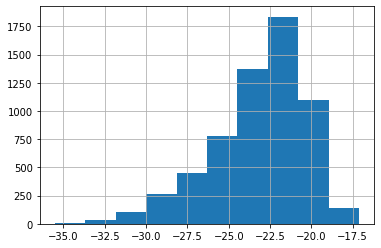

In [57]:
binders_test_df['score_lp_0'].hist()

<AxesSubplot:xlabel='score_lp_1', ylabel='data_type'>

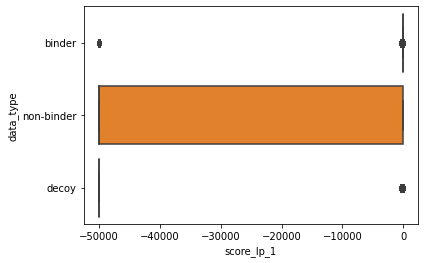

In [145]:
import seaborn as sns
sns.boxplot(data=df, x='score_lp_1', y='data_type')

In [140]:
df_decoy = per_allele_per_run_per_split_decoy_scores_df[ALLELES[0]][0][0]

In [141]:
df_decoy

,peptide,length,score
2,LPPGDRDKL,9,-25.516470
5,RVDEPLVDP,9,-26.297430
15,VEAEKQAAL,9,-24.097852
16,YVTVKPSQS,9,-27.657415
23,DRSVIWSKS,9,-32.676186
...,...,...,...
199979,YEAEKIEYN,9,-28.530485
199982,ATADDLIDV,9,-22.764720
199984,GRQQHQGIL,9,-29.346701
199987,VSDRGSWRD,9,-31.285915


In [142]:
sc = df_decoy['score'].copy()

In [143]:
sc

2        -25.516470
5        -26.297430
15       -24.097852
16       -27.657415
23       -32.676186
            ...    
199979   -28.530485
199982   -22.764720
199984   -29.346701
199987   -31.285915
199995   -23.323687
Name: score, Length: 40024, dtype: float64

<AxesSubplot:xlabel='score'>

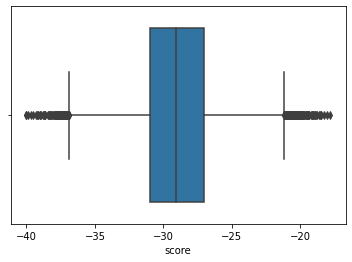

In [144]:
sns.boxplot( x=df_decoy['score'])

In [146]:
df_decoy = per_allele_per_run_per_split_decoy_scores_df[ALLELES[0]][1][0]

In [147]:
df_decoy

,peptide,length,score
2,LPPGDRDKL,9,-25.163315
5,RVDEPLVDP,9,-26.245902
15,VEAEKQAAL,9,-24.079156
16,YVTVKPSQS,9,-27.875029
23,DRSVIWSKS,9,-31.892450
...,...,...,...
199979,YEAEKIEYN,9,-28.875808
199982,ATADDLIDV,9,-22.752946
199984,GRQQHQGIL,9,-29.275705
199987,VSDRGSWRD,9,-31.133207
